# 02. 상담 예제 1 — "카드가 안 긁히는데 어떻게 해야 하나요?" (clarification loop)

첫 번째 상담 예제입니다. 고객 문의에 **구체 정보가 없어서**, agent가 D5(정보 충분성)에서 `need_clarification`을 판정하고 **되묻는 질문을 생성 -> 고객 답변 수신 -> 재판정**하는 recursive loop를 돕니다.

예상 경로:
```
D1(guardrail) -> D2(routing) -> D5(need_clarification) -> 되묻기/답변 -> D5(info_sufficient)
-> D3(tool 선택) -> tool 성공 -> D6(goal_met) -> 요약 -> D7(no_risk) -> D4(resolve) -> 최종 응답
```

같은 질문을 **① Haiku 판단**으로, **② SGLang 판단**으로 각각 실행하며 STEP별 출력을 관찰하고, 마지막에 수행시간을 비교합니다. (응답 생성은 양쪽 모두 Sonnet 4.5 — 차이는 판단 계층뿐)

In [1]:
import sys; sys.path.insert(0, "/home/ubuntu/LLMRouter/OpenSource/workshop")  # ws_common 경로
import ws_common as W
graphs, client = W.make_graphs()
sc = W.SCENARIOS[1]
print("시나리오:", sc["title"])
print("고객 질문:", sc["question"])
print("script(실습 재현용 사전 설정):", sc["script"])

시나리오: 모호한 문의 -> clarification loop
고객 질문: 카드가 안 긁히는데 어떻게 해야 하나요?
script(실습 재현용 사전 설정): {'vague': True, 'clarify_reply': '어제부터 오프라인 매장 단말기에서만 승인이 거절돼요. 관련 정보: Visa 체크카드(끝자리 7712), 마지막 시도 2026-10-27 TechMart 강남점, 금액 45,000원입니다.', 'no_info_reply': '지금 알려드릴 수 있는 정보는 그게 전부예요.', 'tool_outcomes': ['success'], 'risk_flag': False, 'kyc_result': None}


## 전체 workflow에서 이 시나리오의 위치

이번 시나리오가 지나는 경로(빨간 테두리): 접수 심사 -> 업무 분류 -> **되묻기 loop(clarify_gate <-> ask_clarify)** -> tool 1회 성공 -> 요약 -> 리스크 이상 없음 -> 종결. KYC sub-flow와 give_up 경로는 이번에는 지나가지 않습니다.

배정 상담팀(빨간 표시): **cards(카드 발급/배송)** — 카드 오작동 문의이므로 cards 팀 tool(card_troubleshoot)로 처리됩니다.
> 참고: 이 다이어그램은 실행되는 LangGraph에서 자동 생성된 것이 아니라, `ws_common.py`의 한글 캡션 사전(`KO_NODES`/`KO_EDGES`)을 노드 이름 기준으로 그린 **시각화 전용 그림**입니다 (상세 설명: `01_build_agent.ipynb` 참조).


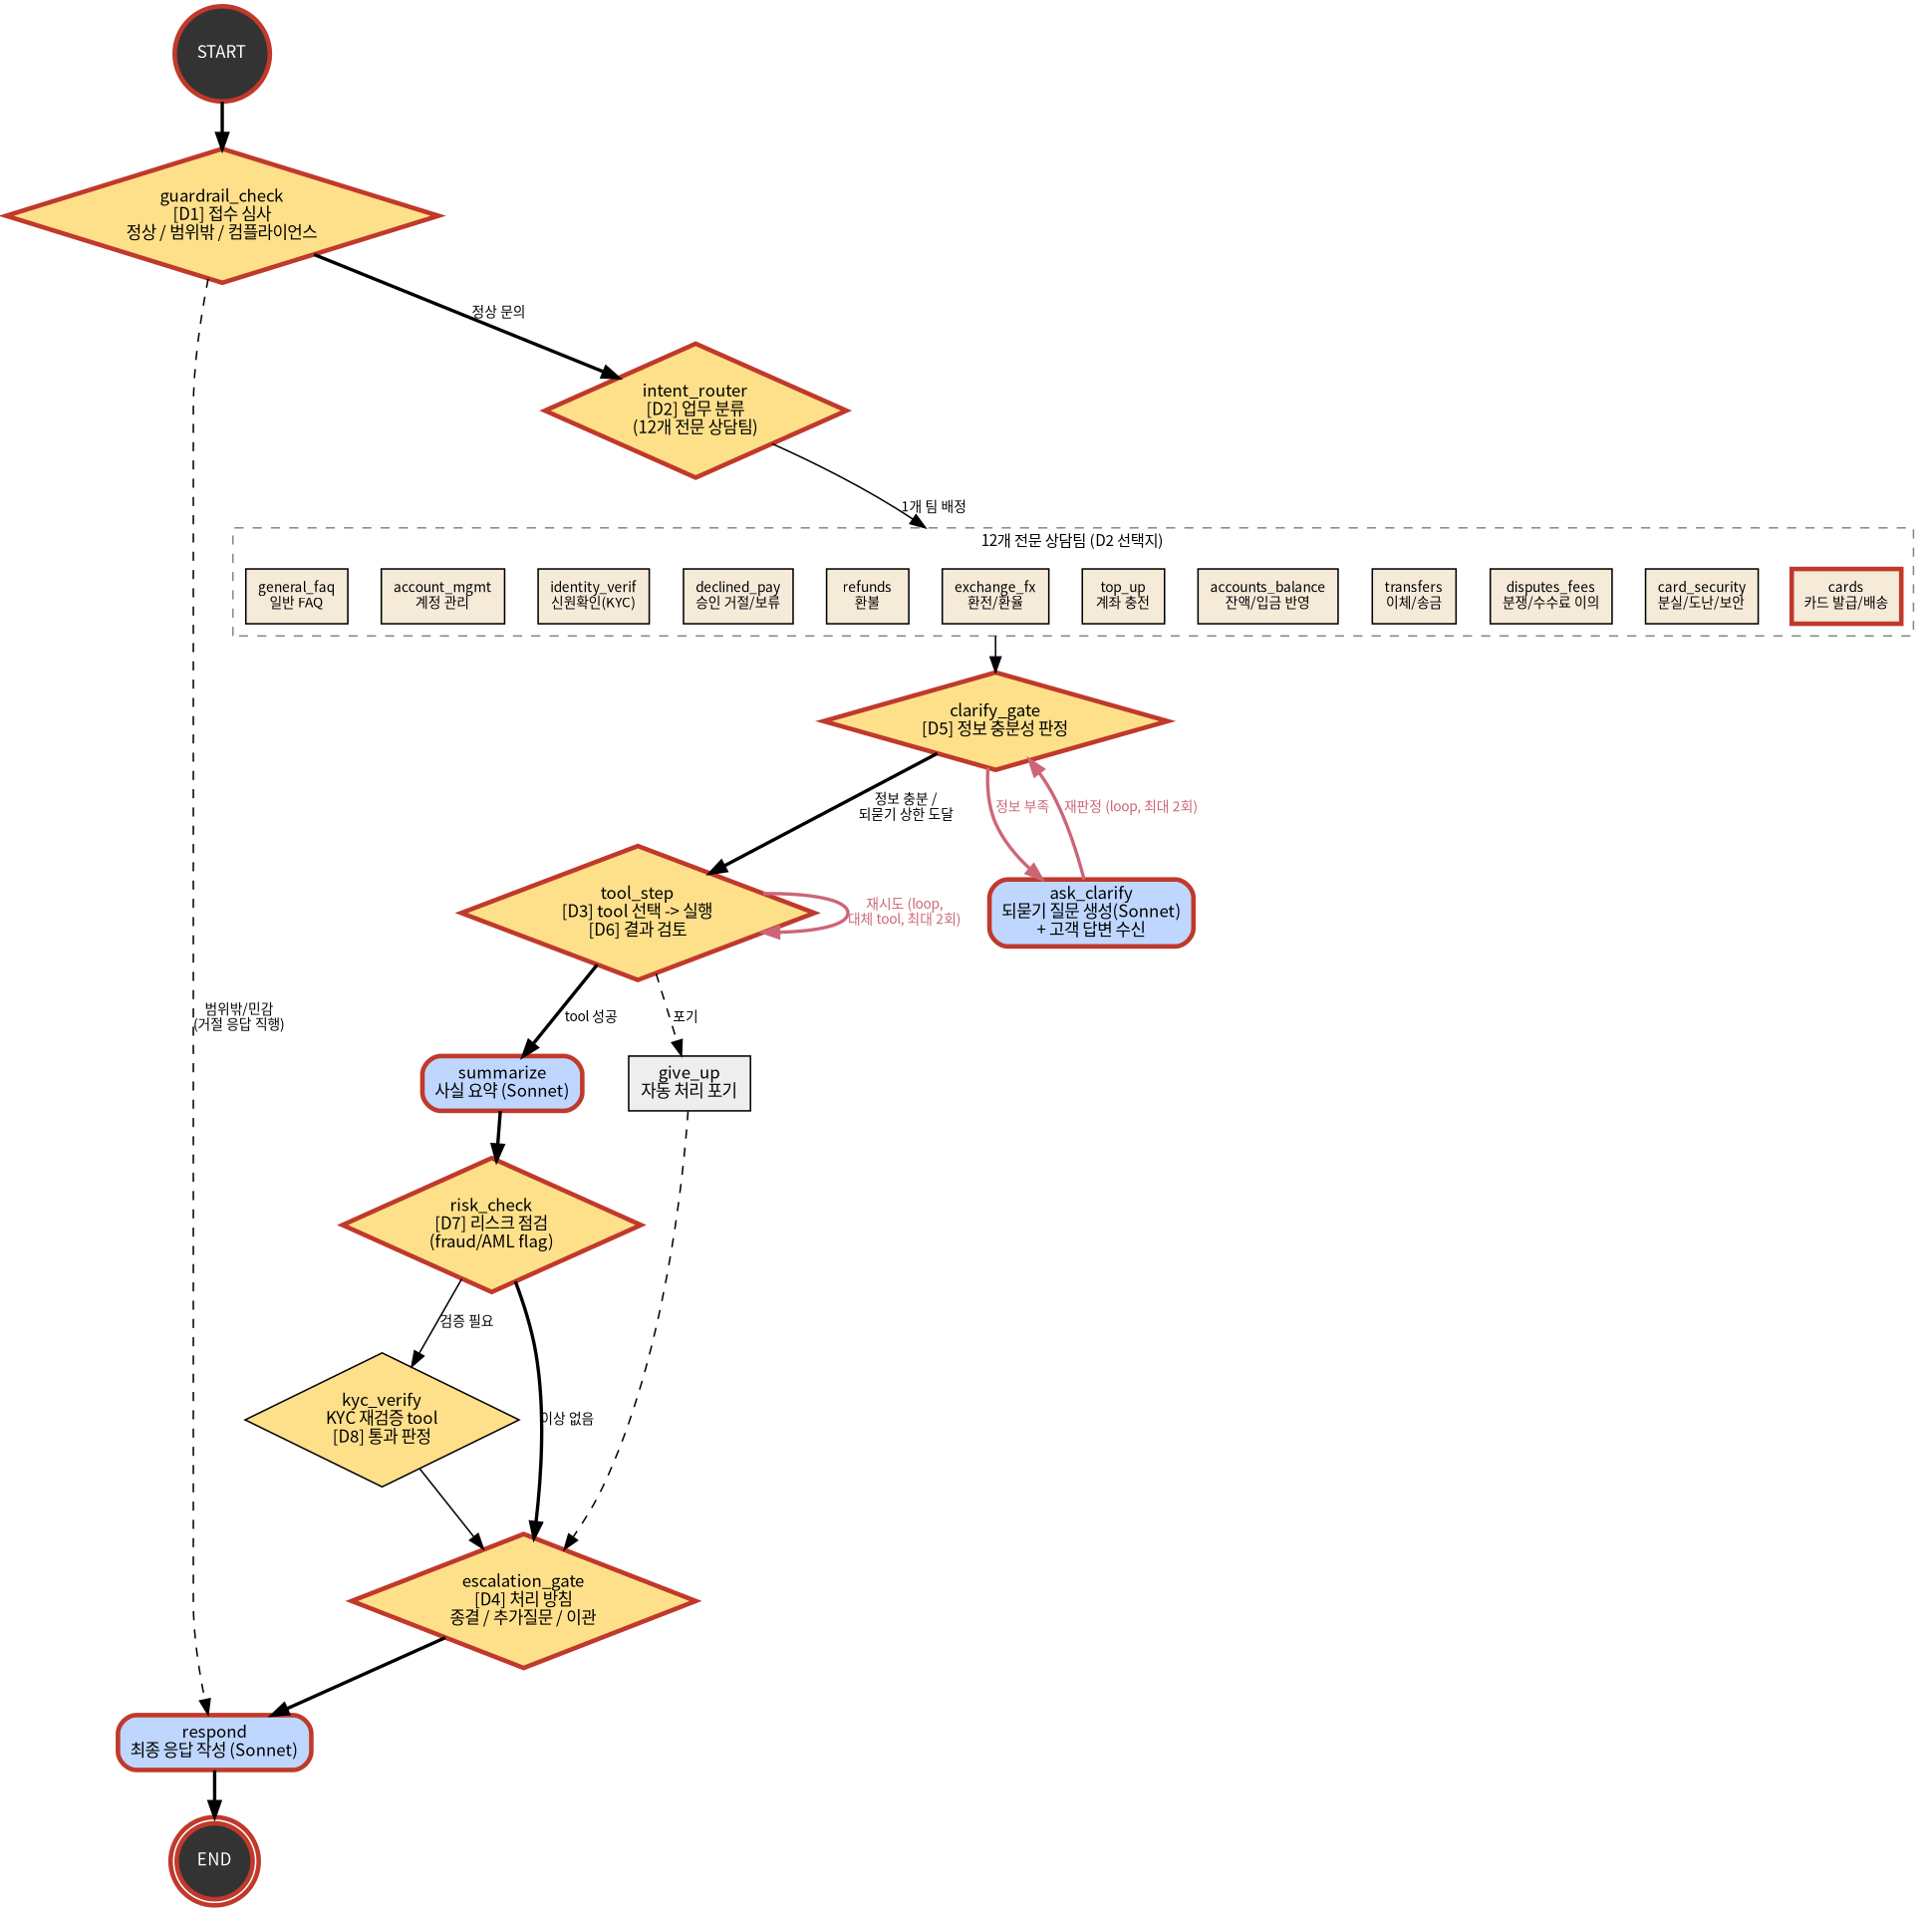

In [2]:
W.draw_graph(highlight=W.SCENARIO_PATHS[1], show_teams=True, width=760)

## ① Haiku 4.5가 판단하는 agent로 실행

각 STEP에서 어떤 노드가 어떤 판정(label)을 몇 ms에 내리는지, 되묻는 질문과 고객 답변, 최종 응답까지 그대로 출력됩니다. **판정 한 번마다 600ms 이상** 걸리는 것을 눈여겨보세요.

In [3]:
res_haiku = W.run_verbose(graphs["Haiku"], sc["question"], sc["script"], "Haiku")


[Haiku] 고객: 카드가 안 긁히는데 어떻게 해야 하나요?

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (940ms)

STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> cards   (618ms)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> need_clarification   (678ms)

STEP 4 ▶ ask_clarify — 되묻기: Sonnet이 질문 생성 -> 고객 답변 수신
      생성(Sonnet 4.5)   (2,384ms)
      상담 agent: 어떤 카드가 안 긁히시나요? 체크카드인가요, 신용카드인가요? 카드 번호 뒷 4자리를 알려주시겠어요?
      고객: 어제부터 오프라인 매장 단말기에서만 승인이 거절돼요. 관련 정보: Visa 체크카드(끝자리 7712), 마지막 시도 2026-10-27 TechMart 강남점, 금액 45,000원입니다.

STEP 5 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (684ms)

STEP 6 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> card_troubleshoot   (691ms)
      tool 실행: card_troubleshoot   (0.0ms)
      판정[D6] -> goal_met   (630ms)

STEP 7 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (3,147ms)
      요약(

## ② SGLang(Qwen3-VL-8B) 판단으로 실행

같은 그래프, 같은 질문입니다. 판정이 **30-50ms**에 끝나고 **confidence**가 함께 찍히는 점이 다릅니다.

In [4]:
res_sglang = W.run_verbose(graphs["SGLang"], sc["question"], sc["script"], "SGLang")


[SGLang] 고객: 카드가 안 긁히는데 어떻게 해야 하나요?

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (53ms, confidence 1.000)

STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> cards   (34ms, confidence 1.000)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> need_clarification   (33ms, confidence 1.000)

STEP 4 ▶ ask_clarify — 되묻기: Sonnet이 질문 생성 -> 고객 답변 수신
      생성(Sonnet 4.5)   (2,463ms)
      상담 agent: 어떤 카드인가요? (신용카드 또는 체크카드 번호 끝 4자리를 알려주시겠어요?)
      고객: 어제부터 오프라인 매장 단말기에서만 승인이 거절돼요. 관련 정보: Visa 체크카드(끝자리 7712), 마지막 시도 2026-10-27 TechMart 강남점, 금액 45,000원입니다.

STEP 5 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (37ms, confidence 1.000)

STEP 6 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> card_troubleshoot   (34ms, confidence 1.000)
      tool 실행: card_troubleshoot   (0.0ms)
      판정[D6] -> goal_met   (34ms, confidence 1.000)

STEP 7 

## ③ 수행시간 비교

생성(Sonnet) 시간은 양쪽이 비슷하고, **판단 계층의 시간이 통째로 사라지는 것**이 핵심입니다.

In [6]:
W.compare(res_haiku, res_sglang)

| 지표 | Haiku | SGLang |
|---|---:|---:|
| 결정 횟수 | 8 | 8 |
| **결정 latency 합계** | **6,159ms** | **299ms** |
| 생성(LLM) latency | 10,571ms | 11,807ms |
| e2e | 16,739ms | 12,115ms |

**결정 계층 속도 차이: 20.6x** (e2e 단축 4,625ms)

**결정별 latency**

| 노드 | 결정 | Haiku | SGLang | 판정 label |
|---|---|---:|---:|---|
| guardrail_check | D1 | 910ms | 53ms | in_scope (동일) |
| intent_router | D2 | 642ms | 34ms | cards (동일) |
| clarify_gate | D5 | 1,174ms | 33ms | need_clarification (동일) |
| clarify_gate | D5 | 692ms | 37ms | info_sufficient (동일) |
| tool_select | D3 | 652ms | 35ms | card_troubleshoot (동일) |
| tool_review | D6 | 654ms | 35ms | goal_met (동일) |
| risk_check | D7 | 667ms | 37ms | no_risk (동일) |
| escalation_gate | D4 | 767ms | 36ms | resolve (동일) |

**관찰 포인트**
- 되묻기 loop 때문에 D5가 두 번 실행됩니다 — loop가 돌수록 판단 횟수가 늘고, 판단이 느린 backend일수록 누적 격차가 커집니다.
- 두 arm의 판정 label이 같은지 비교해 보세요(비교표 우측). label이 같다면 이 대화에서는 품질 손실 없이 속도만 얻은 것입니다.
- 다음: `03_scenario2_retry.ipynb` — tool이 실패했을 때 agent가 스스로 복구하는 loop.